### Assignment 4 — One- and Two-Sample Tests ###

Participants:
- Dimitar Asenov Nizamov - 34468
- Marius Marcoci - 345963
- Plamen Plamenov Michev - 343810

## Table of contents

- [Setup — imports and data](#setup)
- [Part 1 — One-sample decisions](#part1)
    - [Mean sensor error](#p1-mean-sensor-error)
        - [a) $H_0$, $H_1$, $\alpha$ and one-sample $t$ test](#p1a)
        - [b) Interpreting the $p$-value, decision and conclusion](#p1b)
        - [c) 95% $t$ interval, duality and practical importance](#p1c)
    - [False-rejection probability](#p1-false-rejection-probability)
        - [d) One-sided exact binomial test](#p1d)
        - [e) Wilson interval vs. one-sided exact test](#p1e)
        - [f) Type I and Type II errors](#p1f)
- [Part 2 — Independent coating processes](#part2)
    - [a) Independent vs. paired, group summaries and boxplots](#p2a)
    - [b) Welch two-sample $t$ test and 95% interval](#p2b)
    - [c) Assumption diagnostics](#p2c)
    - [d) Interval vs. zero and 8-hour threshold, recommendation](#p2d)
- [Part 3 — Paired building-energy measurements](#part3)
    - [a) Observational unit, pairs and difference summary](#p3a)
    - [b) Paired plots and diagnostics of differences](#p3b)
    - [c) Paired $t$ test and 95% interval for $\mu_D$](#p3c)
    - [d) Value of pairing and practical recommendation](#p3d)
- [Part 4 — Comparing two independent proportions](#part4)
    - [a) Unit, outcome, populations, assumptions and hypotheses](#p4a)
    - [b) Sample proportions, difference and 95% interval](#p4b)
    - [c) Two-proportion $z$ test](#p4c)
    - [d) Random sampling, random assignment and causation](#p4d)
- [Part 5 — AI-use and conclusion](#part5)
    - [AI-use](#ai)
    - [Overall conclusion](#conclusion)

<a id="setup"></a>
## Setup — imports and data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, norm, ttest_1samp, ttest_ind, ttest_rel, binomtest, shapiro, probplot
from statsmodels.stats.proportion import proportion_confint

sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")
coating = pd.read_csv("data/assignment04_coating_durability.csv")
energy = pd.read_csv("data/assignment04_energy_retrofit.csv")

display(sensors.head())
display(access.head())
display(coating.head())
display(energy.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


,specimen_id,process,durability_h
0,1,standard,112.45
1,2,standard,109.55
2,3,standard,131.35
3,4,standard,130.96
4,5,standard,110.15


,building_id,before_kwh_day,after_kwh_day
0,1,91.57,87.75
1,2,95.33,90.14
2,3,85.20,85.61
3,4,75.96,64.30
4,5,85.33,81.90


<a id="part1"></a>
## Part 1 — One-sample decisions

<a id="p1-mean-sensor-error"></a>
### Mean sensor error

The engineering team asks whether population mean calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm C$ are regarded as small in practice.

<a id="p1a"></a>
#### a) State $H_0$, the two-sided $H_1$, and $\alpha=0.05$. Use a one-sample $t$ procedure and report the sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

- **Population and parameter:** all temperature sensors of this type; $\mu$ is the population mean calibration error (sensor reading − reference temperature) in °C.
- **Observational unit and design:** one sensor; a single sample of 64 independently selected sensors.
- **Hypotheses (two-sided, fixed before the analysis):** $H_0:\mu=0\ ^\circ\mathrm C$ versus $H_1:\mu\neq0\ ^\circ\mathrm C$.
- **Significance level:** $\alpha=0.05$.

In [3]:
x = sensors["calibration_error_c"].to_numpy()
mu0 = 0.0
alpha = 0.05
n = x.size
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)

t_obs = (xbar - mu0) / se
df_t = n - 1
p_two = 2 * t.sf(np.abs(t_obs), df=df_t)
res_1a = ttest_1samp(x, popmean=mu0, alternative="two-sided")

print(f"n = {n}, sample mean = {xbar:.4f} °C, s = {s:.4f} °C, SE = {se:.4f} °C")
print(f"t = ({xbar:.4f} - {mu0}) / {se:.4f} = {t_obs:.4f}, df = n - 1 = {df_t}")
print(f"two-sided p-value = 2 * P(T >= |t|) = {p_two:.4f}")
print("SciPy:", res_1a)

n = 64, sample mean = 0.1883 °C, s = 0.6257 °C, SE = 0.0782 °C
t = (0.1883 - 0.0) / 0.0782 = 2.4069, df = n - 1 = 63
two-sided p-value = 2 * P(T >= |t|) = 0.0190
SciPy: TtestResult(statistic=np.float64(2.4069234365872125), pvalue=np.float64(0.019030535831259087), df=np.int64(63))


<a id="p1b"></a>
#### b) Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the decision and a contextual conclusion without treating the $p$-value as $P(H_0\mid\text{data})$.

**Interpretation of the $p$-value:** assume that the population mean error is exactly 0 °C and that the model assumptions hold (independent sensors, approximately normal errors). Then, over repeated samples of 64 sensors, a $t$ statistic at least as far from 0 as the observed $|t| = 2.41$, in either direction, would occur with probability 0.019. The $p$-value is a tail probability computed *given* $H_0$. It is not $P(H_0\mid\text{data})$, so it does not mean that there is a 1.9% chance that the mean error is zero.

**Decision:** $p = 0.019 < \alpha = 0.05$, so we reject $H_0$.

**Conclusion:** the data provide evidence that the population mean calibration error of these sensors differs from 0 °C. The sample mean of +0.188 °C indicates that the sensors read slightly too high on average.

<a id="p1c"></a>
#### c) Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare it with the practical limits and distinguish statistical significance from practical importance.

In [4]:
ci_1c = t.interval(0.95, df=df_t, loc=xbar, scale=se)
print(f"95% t interval for mu = [{ci_1c[0]:.4f}, {ci_1c[1]:.4f}] °C")
print("0 °C inside the interval?", ci_1c[0] <= mu0 <= ci_1c[1])
print("interval inside the practical limits (-0.50, 0.50) °C?", -0.50 < ci_1c[0] and ci_1c[1] < 0.50)

95% t interval for mu = [0.0320, 0.3446] °C
0 °C inside the interval? False
interval inside the practical limits (-0.50, 0.50) °C? True


**Duality with the two-sided test:** the 95% $t$ interval [0.032, 0.345] °C and the two-sided test at $\alpha = 0.05$ are built from the same estimate, standard error and $t$ distribution with 63 degrees of freedom. Therefore $H_0:\mu=\mu_0$ is rejected at the 5% level exactly when $\mu_0$ lies outside the 95% interval. Here 0 °C lies outside the interval, which matches the rejection with $p = 0.019$. Every value inside the interval would not be rejected by the same test.

**Comparison with the practical limits:** the whole interval lies inside $(-0.50, 0.50)$ °C. Even the upper limit, 0.345 °C, is clearly below 0.50 °C, so all plausible values of the mean error are small in practice.

**Statistical significance vs. practical importance:** the mean error is *statistically significant*: a mean of exactly 0 °C is hard to reconcile with the data. It is *not practically important*: the estimate is 0.19 °C and at most about 0.34 °C is plausible, below the 0.50 °C limit. The $p$-value only says that a difference from zero is detectable; the interval and the engineering limit decide whether its size matters.

<a id="p1-false-rejection-probability"></a>
### False-rejection probability

The pre-specified question is whether the false-rejection probability exceeds the 5% target.

<a id="p1d"></a>
#### d) State the one-sided hypotheses. Perform an exact binomial test and report $\hat p$, the $p$-value, decision, and conclusion.

- **Population and parameter:** all legitimate login attempts under the test conditions; $p$ is the probability that a legitimate attempt is falsely rejected.
- **Observational unit and design:** one staged login attempt; a single sample of 240 independently staged attempts.
- **Hypotheses (one-sided, pre-specified):** $H_0: p \le 0.05$ versus $H_1: p > 0.05$, evaluated at the boundary $p_0 = 0.05$.
- **Significance level:** $\alpha = 0.05$.

In [5]:
y = access["false_reject"].to_numpy()
n_att = y.size
x_rej = int(y.sum())
p_hat = x_rej / n_att
p0 = 0.05

res_1d = binomtest(x_rej, n=n_att, p=p0, alternative="greater")
print(f"n = {n_att}, x = {x_rej}, p_hat = {x_rej}/{n_att} = {p_hat:.4f}")
print(f"exact upper-tail p-value P(X >= {x_rej} | p = {p0}) = {res_1d.pvalue:.4f}")
print("Decision at alpha = 0.05:", "reject H0" if res_1d.pvalue < alpha else "fail to reject H0")

n = 240, x = 20, p_hat = 20/240 = 0.0833
exact upper-tail p-value P(X >= 20 | p = 0.05) = 0.0185
Decision at alpha = 0.05: reject H0


**Decision:** the exact $p$-value is 0.0185 < 0.05, so we reject $H_0$.

**Conclusion:** 20 of the 240 legitimate attempts were rejected ($\hat p = 8.33\%$). If the true false-rejection probability were 5%, 20 or more false rejections among 240 attempts would occur with probability 0.0185. The data therefore provide evidence that, under these test conditions, the false-rejection probability exceeds the 5% target.

<a id="p1e"></a>
#### e) Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson interval is not the exact dual of a one-sided exact test.

In [6]:
wilson = proportion_confint(x_rej, n_att, alpha=0.05, method="wilson")
print(f"two-sided 95% Wilson interval for p = [{wilson[0]:.4f}, {wilson[1]:.4f}] = [{wilson[0]:.2%}, {wilson[1]:.2%}]")

two-sided 95% Wilson interval for p = [0.0546, 0.1252] = [5.46%, 12.52%]


**Plausible values:** the estimate is $\hat p = 8.33\%$, and the 95% Wilson interval [5.46%, 12.52%] gives the false-rejection probabilities that are compatible with the data. The whole interval lies above the 5% target, so the target is plausibly exceeded by between about 0.5 and 7.5 percentage points.

**Why the Wilson interval is not the exact dual of the one-sided exact test:** test–interval duality holds only for a two-sided test and an interval *constructed from the same method*. Both conditions fail here:
- **Different method:** the Wilson interval is obtained from the large-sample score statistic $(\hat p - p_0)/\sqrt{p_0(1-p_0)/n}$, while the exact test uses the binomial distribution directly.
- **Different direction:** the Wilson interval is two-sided at 95% (2.5% in each tail), while the test is one-sided with all 5% in the upper tail.

The decision boundaries of the two methods therefore need not coincide: for a count near the boundary, the exact test could reject while the Wilson lower limit is still below 5%, or the other way round. Here both point in the same direction, but that agreement is not guaranteed, so the Wilson interval is used only as an estimate of plausible values.

<a id="p1f"></a>
#### f) Describe Type I and Type II errors in one of the two one-sample studies and state an operational consequence of each.

We use the false-rejection study, $H_0: p \le 0.05$ versus $H_1: p > 0.05$.

- **Type I error (false positive):** rejecting $H_0$ although the true false-rejection probability is at most 5%, i.e. concluding that the system misses the target when it actually meets it. Its probability is at most $\alpha = 0.05$. **Operational consequence:** the system is unnecessarily retuned or its release is delayed, which costs engineering time. If the retuning makes the system more permissive, it may also accept more unauthorised users.
- **Type II error (false negative):** failing to reject $H_0$ although the true false-rejection probability is above 5%. Its probability is $\beta$, which is larger when $n$ is small or $p$ is only slightly above 0.05. **Operational consequence:** the system is approved although it misses the target, so legitimate users are locked out more often than specified, with more help-desk requests and lost working time.

Since $H_0$ was rejected in d), the only error this decision could contain is a Type I error.

<a id="part2"></a>
## Part 2 — Independent coating processes

The file `assignment04_coating_durability.csv` contains independent specimens from a standard and modified coating process. Let

$$
\delta=\mu_{\text{modified}}-\mu_{\text{standard}},
$$

measured in durability hours. An increase of at least 8 hours is considered practically important.

<a id="p2a"></a>
#### a) Explain why the samples are independent rather than paired. Report group $n$, mean, sample standard deviation, and boxplots.

**Why the samples are independent rather than paired:** each specimen received only one of the two coating processes, so the 48 modified and 44 standard specimens are different, unrelated units. No specimen has a specific, meaningful partner in the other group (the group sizes even differ), and the durability of one standard specimen gives no information about any modified specimen. Matching rows by order or by sorting would invent a pairing that the design does not contain.

- **Population and parameter:** specimens produced by the modified and by the standard process; $\delta=\mu_{\text{modified}}-\mu_{\text{standard}}$ in hours.
- **Observational unit:** one coated specimen; outcome durability in hours.
- **Comparison order (fixed in advance):** modified − standard, so a positive $\delta$ means the modified process lasts longer.

,process,n,mean (h),SD (h)
0,modified,48,132.49,22.19
1,standard,44,117.29,15.75


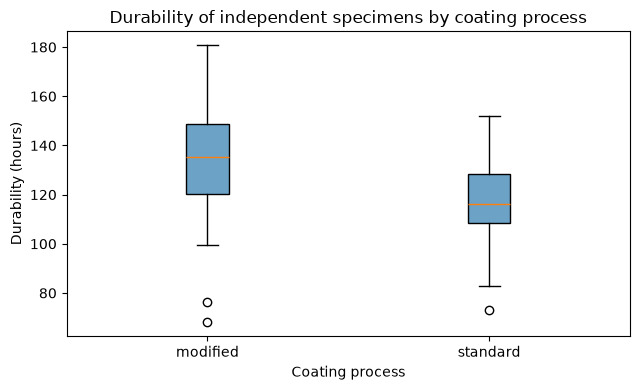

In [7]:
modified = coating.loc[coating["process"] == "modified", "durability_h"].to_numpy()
standard = coating.loc[coating["process"] == "standard", "durability_h"].to_numpy()

summary_2a = pd.DataFrame({
    "process": ["modified", "standard"],
    "n": [modified.size, standard.size],
    "mean (h)": [modified.mean(), standard.mean()],
    "SD (h)": [modified.std(ddof=1), standard.std(ddof=1)],
})
display(summary_2a.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4))
bp = ax.boxplot([modified, standard], patch_artist=True)
ax.set_xticks([1, 2], ["modified", "standard"])
for patch in bp["boxes"]:
    patch.set_facecolor("#6CA2C6")
ax.set_xlabel("Coating process")
ax.set_ylabel("Durability (hours)")
ax.set_title("Durability of independent specimens by coating process")
plt.tight_layout()
plt.show()

<a id="p2b"></a>
#### b) State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and $p$-value. Do not use a preliminary variance test to switch automatically between pooled and Welch procedures.

- **Hypotheses (two-sided):** $H_0:\delta=0$ h versus $H_1:\delta\neq0$ h.
- **Significance level:** $\alpha=0.05$.
- **Method:** Welch's two-sample $t$ procedure, the default for independent means. No variance test is run; the different sample standard deviations are allowed for by Welch's standard error $\sqrt{s_m^2/n_m+s_s^2/n_s}$ and the Welch–Satterthwaite degrees of freedom.

In [8]:
n_m, n_s = modified.size, standard.size
diff_2b = modified.mean() - standard.mean()
se_w = np.sqrt(modified.var(ddof=1) / n_m + standard.var(ddof=1) / n_s)
res_w = ttest_ind(modified, standard, equal_var=False, alternative="two-sided")
df_w = res_w.df
ci_w = t.interval(0.95, df=df_w, loc=diff_2b, scale=se_w)

print(f"estimated difference modified - standard = {modified.mean():.2f} - {standard.mean():.2f} = {diff_2b:.2f} h")
print(f"SE = sqrt(s_m^2/n_m + s_s^2/n_s) = {se_w:.3f} h")
print(f"Welch t = {res_w.statistic:.3f}, approximate df = {df_w:.2f}, two-sided p-value = {res_w.pvalue:.6f}")
print(f"95% Welch CI for delta = [{ci_w[0]:.2f}, {ci_w[1]:.2f}] h")

estimated difference modified - standard = 132.49 - 117.29 = 15.20 h
SE = sqrt(s_m^2/n_m + s_s^2/n_s) = 3.987 h
Welch t = 3.812, approximate df = 84.84, two-sided p-value = 0.000260
95% Welch CI for delta = [7.27, 23.13] h


**Decision:** $p = 0.00026 < 0.05$, so we reject $H_0$. The data provide evidence that the mean durability differs between the processes; the modified process is estimated to last 15.20 h longer on average (95% CI [7.27, 23.13] h).

<a id="p2c"></a>
#### c) Assess independence from the design and distribution shape and unusual observations from group plots or residual diagnostics. State what the plots cannot establish.

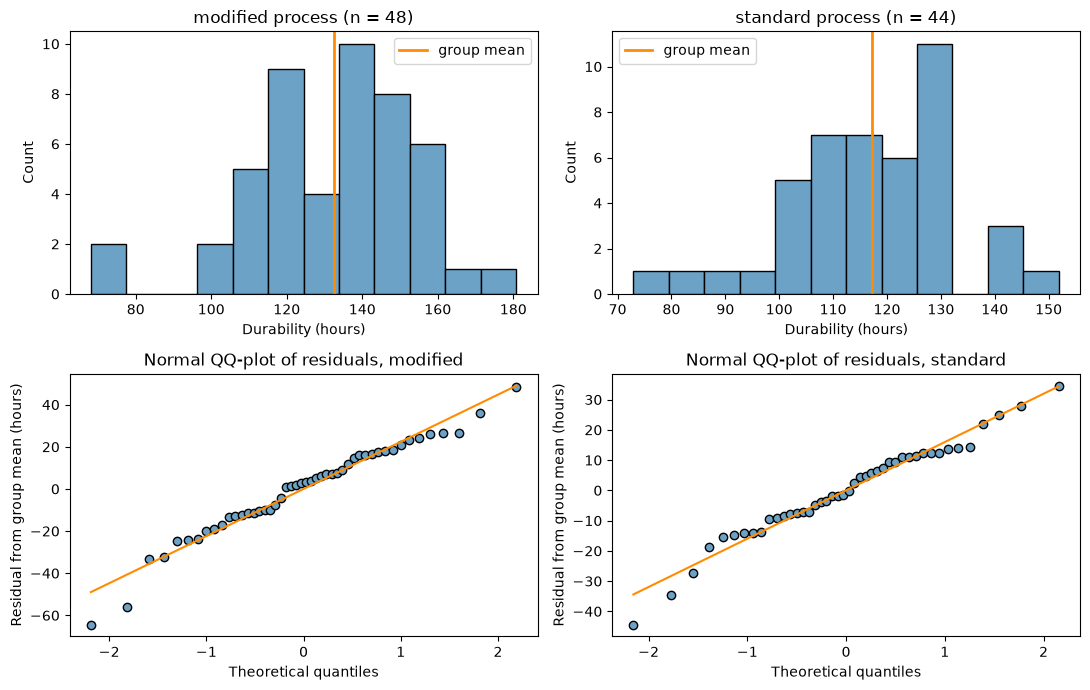

modified: min = 68.12 h, max = 180.77 h, points beyond 1.5 IQR = 2, Shapiro–Wilk W = 0.970, p = 0.247
standard: min = 72.93 h, max = 151.87 h, points beyond 1.5 IQR = 1, Shapiro–Wilk W = 0.977, p = 0.523


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, (name, values) in enumerate([("modified", modified), ("standard", standard)]):
    axes[0, col].hist(values, bins=12, color="#6CA2C6", edgecolor="black")
    axes[0, col].axvline(values.mean(), color="#FF8C00", lw=2, label="group mean")
    axes[0, col].set_xlabel("Durability (hours)")
    axes[0, col].set_ylabel("Count")
    axes[0, col].set_title(f"{name} process (n = {values.size})")
    axes[0, col].legend()

    probplot(values - values.mean(), dist="norm", plot=axes[1, col])
    axes[1, col].get_lines()[0].set_markerfacecolor("#6CA2C6")
    axes[1, col].get_lines()[0].set_markeredgecolor("black")
    axes[1, col].get_lines()[1].set_color("#FF8C00")
    axes[1, col].set_ylabel("Residual from group mean (hours)")
    axes[1, col].set_title(f"Normal QQ-plot of residuals, {name}")
plt.tight_layout()
plt.show()

for name, values in [("modified", modified), ("standard", standard)]:
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    n_out = int(np.sum((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)))
    W_g, p_g = shapiro(values)
    print(f"{name}: min = {values.min():.2f} h, max = {values.max():.2f} h, "
          f"points beyond 1.5 IQR = {n_out}, Shapiro–Wilk W = {W_g:.3f}, p = {p_g:.3f}")

**Independence (from the design):** the specimens are separate units that each received one process, so independence between the groups follows from the design. Independence *within* each group requires that specimens were not, for example, cut from the same panel or tested together on one rig in one session; this has to be documented by the study, not read from the data.

**Distribution shape:** both histograms are single-peaked. Both groups have a longer lower tail: the modified group through two isolated low specimens (68.12 and 76.48 h), the standard group through a spread of low values down to 72.93 h. In both QQ-plots of the residuals (value − group mean), the points follow the line closely in the middle, with the lowest few values falling below it. The supplementary Shapiro–Wilk tests give $p = 0.247$ (modified) and $p = 0.523$ (standard), so there is no clear evidence against normality. The modified group is more spread out (SD 22.19 h vs. 15.75 h), which Welch's procedure allows for.

**Unusual observations:** beyond 1.5 IQR there are 2 low values in the modified group (lowest 68.12 h) and 1 in the standard group (72.93 h). They are not extreme enough to dominate the group means, and with 48 and 44 specimens the sampling distribution of each mean is close to normal, so the Welch procedure is reasonable. These specimens should not be removed unless a documented cause (e.g. a defective specimen) is found.

**What the plots cannot establish:** they cannot show that the specimens are independent, that they represent future production of each process, that the processes were assigned so that the difference is caused by the process, or that durability was measured in the same way in both groups. They also cannot prove normality; they only show no clear departure from it.

<a id="p2d"></a>
#### d) Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation that reflects statistical uncertainty and practical importance.

**Comparison with zero:** the 95% interval [7.27, 23.13] h excludes 0, so an increase in mean durability is supported (consistent with $p = 0.00026$).

**Comparison with the 8-hour threshold:** the estimate of 15.20 h is almost twice the threshold, and most of the interval lies above 8 h. The lower limit of 7.27 h, however, is slightly below 8 h. Values from 7.27 to 23.13 h are plausible, so an increase just short of the practically important size cannot be excluded: a gain of at least 8 h is not established at 95% confidence.

**Recommendation:** the modified process is preferred: the data support an increase in mean durability, and most plausible values exceed the 8 hours that matter in practice, although the lower limit of 7.27 h does not. If switching is costly, a confirmation study with more specimens is advisable to narrow the interval and rule out a gain below 8 h. The causes of the two very low modified specimens and the larger spread of the modified process (SD 22.19 vs. 15.75 h) should also be checked before production.

<a id="part3"></a>
## Part 3 — Paired building-energy measurements

The file `assignment04_energy_retrofit.csv` records energy use for the same 36 buildings before and after a control-system retrofit. Define the paired difference

$$
D=\text{before}-\text{after},
$$

so a positive value represents a reduction.

<a id="p3a"></a>
#### a) Explain the observational unit and why the rows form genuine pairs. Create the difference column and report its mean, standard deviation, and standard error.

**Observational unit:** one building, measured twice: energy use before and after the control-system retrofit, in kWh/day.

**Why the rows form genuine pairs:** both values in a row come from the *same building*, so each "before" value has a specific and meaningful partner "after" value. Size, use and insulation of a building affect both measurements, and the within-building difference removes this building-to-building variation. The pairing comes from the design (the same 36 buildings), not from the row order.

- **Population and parameter:** buildings of this type that receive the retrofit; $\mu_D$ is the population mean of $D=\text{before}-\text{after}$ in kWh/day.
- **Comparison order (fixed in advance):** before − after, so a positive $D$ is a reduction in energy use.

In [10]:
energy["D"] = energy["before_kwh_day"] - energy["after_kwh_day"]
d = energy["D"].to_numpy()
n_d = d.size
d_bar = d.mean()
s_d = d.std(ddof=1)
se_d = s_d / np.sqrt(n_d)

print(f"number of pairs n = {n_d}")
print(f"mean difference d_bar = {d_bar:.3f} kWh/day")
print(f"SD of differences s_D = {s_d:.3f} kWh/day")
print(f"SE = s_D/sqrt(n) = {s_d:.3f}/sqrt({n_d}) = {se_d:.3f} kWh/day")

number of pairs n = 36
mean difference d_bar = 4.823 kWh/day
SD of differences s_D = 4.504 kWh/day
SE = s_D/sqrt(n) = 4.504/sqrt(36) = 0.751 kWh/day


<a id="p3b"></a>
#### b) Plot the paired values and the distribution or QQ-plot of differences. Diagnose the differences—not the two raw columns separately—for the paired $t$ procedure.

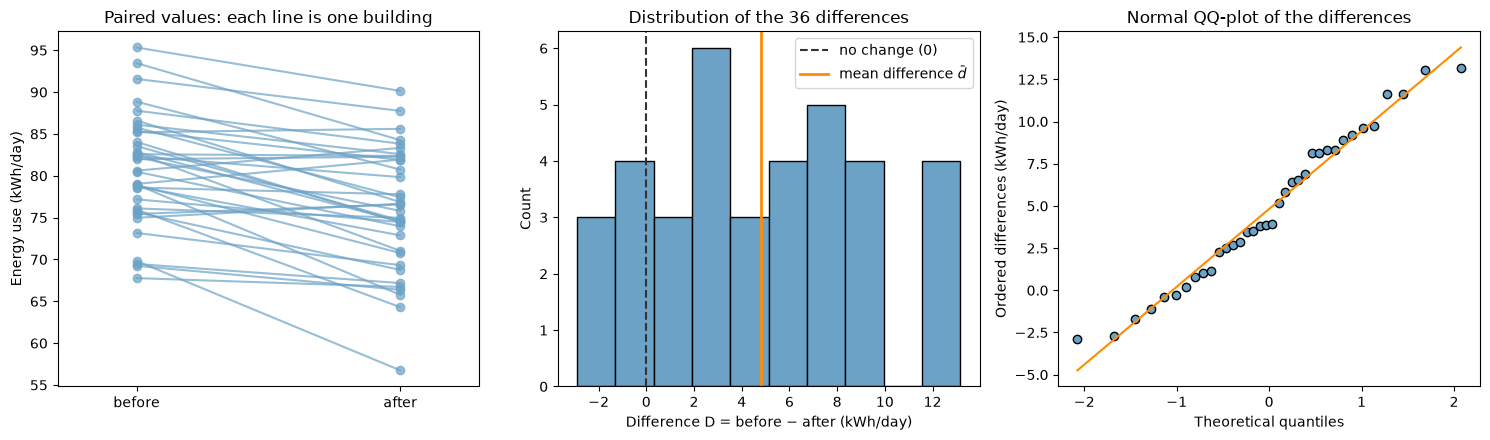

differences: min = -2.90, max = 13.17 kWh/day, points beyond 1.5 IQR = 0
Shapiro–Wilk on the differences: W = 0.969, p = 0.403


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for _, row in energy.iterrows():
    axes[0].plot([0, 1], [row["before_kwh_day"], row["after_kwh_day"]], color="#6CA2C6", alpha=0.7, marker="o")
axes[0].set_xticks([0, 1], ["before", "after"])
axes[0].set_xlim(-0.3, 1.3)
axes[0].set_ylabel("Energy use (kWh/day)")
axes[0].set_title("Paired values: each line is one building")

axes[1].hist(d, bins=10, color="#6CA2C6", edgecolor="black")
axes[1].axvline(0, color="0.2", linestyle="--", label="no change (0)")
axes[1].axvline(d_bar, color="#FF8C00", lw=2, label=r"mean difference $\bar d$")
axes[1].set_xlabel("Difference D = before − after (kWh/day)")
axes[1].set_ylabel("Count")
axes[1].set_title("Distribution of the 36 differences")
axes[1].legend()

probplot(d, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set_markerfacecolor("#6CA2C6")
axes[2].get_lines()[0].set_markeredgecolor("black")
axes[2].get_lines()[1].set_color("#FF8C00")
axes[2].set_ylabel("Ordered differences (kWh/day)")
axes[2].set_title("Normal QQ-plot of the differences")

plt.tight_layout()
plt.show()

q1, q3 = np.percentile(d, [25, 75])
n_out_d = int(np.sum((d < q1 - 1.5 * (q3 - q1)) | (d > q3 + 1.5 * (q3 - q1))))
W_d, p_sw_d = shapiro(d)
print(f"differences: min = {d.min():.2f}, max = {d.max():.2f} kWh/day, points beyond 1.5 IQR = {n_out_d}")
print(f"Shapiro–Wilk on the differences: W = {W_d:.3f}, p = {p_sw_d:.3f}")

**Paired values:** most lines slope downwards, so most buildings use less energy after the retrofit. Buildings with high use before tend to have high use after as well; this shared building level is what the pairing removes.

**Diagnosis of the differences:** the paired $t$ procedure is a one-sample $t$ procedure on the 36 differences, so it requires the differences, not the two raw columns, to be independent and approximately normal.
- **Shape:** the histogram of $D$ is fairly flat and roughly symmetric around $\bar d = 4.82$ kWh/day, with no strong skew and values from −2.90 to 13.17 kWh/day.
- **QQ-plot:** the points lie close to the straight line, with no curvature or isolated extreme points.
- **Numerical checks:** no difference lies beyond 1.5 IQR, and the supplementary Shapiro–Wilk test ($W = 0.969$, $p = 0.403$) shows no clear evidence against normality.

With 36 pairs and no outliers, the paired $t$ procedure is reasonable. Independence between buildings cannot be seen in these plots; it relies on the buildings being separate units that do not, for example, share one control system.

<a id="p3c"></a>
#### c) Test $H_0:\mu_D=0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using `ttest_rel` or an equivalent one-sample procedure applied to the differences.

- **Hypotheses (two-sided):** $H_0:\mu_D=0$ kWh/day versus $H_1:\mu_D\neq0$ kWh/day.
- **Significance level:** $\alpha=0.05$.
- **Method:** paired $t$ procedure with $n-1 = 35$ degrees of freedom, where $n=36$ is the number of pairs.

In [12]:
res_p = ttest_rel(energy["before_kwh_day"], energy["after_kwh_day"], alternative="two-sided")
ci_d = t.interval(0.95, df=n_d - 1, loc=d_bar, scale=se_d)

print(f"t = d_bar / SE = {d_bar:.3f} / {se_d:.3f} = {d_bar / se_d:.3f}, df = {n_d - 1}")
print("ttest_rel:", res_p)
print(f"95% CI for mu_D = [{ci_d[0]:.2f}, {ci_d[1]:.2f}] kWh/day")

t = d_bar / SE = 4.823 / 0.751 = 6.425, df = 35
ttest_rel: TtestResult(statistic=np.float64(6.425162898637381), pvalue=np.float64(2.135022086310364e-07), df=np.int64(35))
95% CI for mu_D = [3.30, 6.35] kWh/day


**Decision:** $t = 6.43$ with 35 degrees of freedom gives a two-sided $p$-value of $2.1\times10^{-7} < 0.05$, so we reject $H_0$. The 95% interval [3.30, 6.35] kWh/day for $\mu_D$ excludes 0, consistent with the test: the data provide evidence that mean energy use is lower after the retrofit.

<a id="p3d"></a>
#### d) Explain why an independent-samples test would discard useful pairing. Interpret the estimated reduction and interval in kWh/day and state a practical recommendation.

In [13]:
before = energy["before_kwh_day"].to_numpy()
after = energy["after_kwh_day"].to_numpy()
r = np.corrcoef(before, after)[0, 1]
se_indep = np.sqrt(before.var(ddof=1) / n_d + after.var(ddof=1) / n_d)

print(f"SD before = {before.std(ddof=1):.2f}, SD after = {after.std(ddof=1):.2f}, SD of differences = {s_d:.2f} kWh/day")
print(f"correlation between before and after = {r:.3f}")
print(f"SE ignoring the pairing = {se_indep:.3f} kWh/day vs paired SE = {se_d:.3f} kWh/day")

SD before = 6.63, SD after = 7.35, SD of differences = 4.50 kWh/day
correlation between before and after = 0.797
SE ignoring the pairing = 1.651 kWh/day vs paired SE = 0.751 kWh/day


**Why an independent-samples test would discard useful pairing:** an independent-samples test treats the before and after values as two unrelated samples, so its standard error contains the full building-to-building variation (SD 6.63 and 7.35 kWh/day). The two measurements on the same building are, however, strongly correlated ($r = 0.797$). For paired data, $\operatorname{Var}(D)=\sigma_X^2+\sigma_Y^2-2\rho\,\sigma_X\sigma_Y$, so the positive correlation removes most of that variation: the SD of the differences is only 4.50 kWh/day. Ignoring the pairing would give a standard error of 1.651 kWh/day instead of 0.751 kWh/day, more than twice as large, and hence a much wider interval and less power. It would also wrongly treat the 72 measurements as independent observations.

**Interpretation in kWh/day:** the retrofit is estimated to reduce mean energy use by 4.82 kWh/day per building. Mean reductions between 3.30 and 6.35 kWh/day are compatible with the data (95% CI), so even the smallest plausible value is a clear saving.

**Practical recommendation:** the retrofit can be recommended for similar buildings if a saving of roughly 3–6 kWh/day per building justifies its cost. Because this is a before–after design without a comparison group, part of the reduction could come from differences in weather or use between the two periods; this should be checked before the saving is attributed to the retrofit alone.

<a id="part4"></a>
## Part 4 — Comparing two independent proportions

Two independently assigned software configurations were evaluated using separate requests. Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define the risk difference as $p_A-p_B$.

<a id="p4a"></a>
#### a) State the observational unit, binary outcome, populations, assumptions, comparison order, and two-sided hypotheses.

- **Observational unit:** one request.
- **Binary outcome:** whether the request is an SLA failure (yes/no).
- **Populations:** requests served under configuration A and requests served under configuration B under the test conditions; $p_A$ and $p_B$ are the SLA-failure probabilities.
- **Assumptions:** requests are independent within and between the groups (separate requests, independently assigned configurations), each configuration has one constant failure probability, and there are enough failures and non-failures in each group for the large-sample normal approximation (38/262 and 22/298, all at least 10; see b).
- **Comparison order (fixed in advance):** the risk difference $p_A-p_B$, so a positive value means more failures under A.
- **Hypotheses (two-sided):** $H_0:p_A=p_B$ (i.e. $p_A-p_B=0$) versus $H_1:p_A\neq p_B$, at $\alpha=0.05$.

<a id="p4b"></a>
#### b) Calculate both sample proportions, their difference in percentage points, and a 95% confidence interval using separate estimated variances.

In [14]:
x_A, n_A = 38, 300
x_B, n_B = 22, 320
p_A, p_B = x_A / n_A, x_B / n_B
rd = p_A - p_B

se_rd = np.sqrt(p_A * (1 - p_A) / n_A + p_B * (1 - p_B) / n_B)
z_crit = norm.ppf(0.975)
ci_rd = (rd - z_crit * se_rd, rd + z_crit * se_rd)

print(f"A: failures = {x_A}, non-failures = {n_A - x_A}, p_A = {x_A}/{n_A} = {p_A:.4f}")
print(f"B: failures = {x_B}, non-failures = {n_B - x_B}, p_B = {x_B}/{n_B} = {p_B:.4f}")
print(f"risk difference p_A - p_B = {rd:.4f} = {100 * rd:.2f} percentage points")
print(f"SE (separate variances) = {se_rd:.5f}")
print(f"95% CI = {rd:.4f} ± {z_crit:.3f} x {se_rd:.5f} = [{ci_rd[0]:.4f}, {ci_rd[1]:.4f}]"
      f" = [{100 * ci_rd[0]:.2f}, {100 * ci_rd[1]:.2f}] percentage points")

A: failures = 38, non-failures = 262, p_A = 38/300 = 0.1267
B: failures = 22, non-failures = 298, p_B = 22/320 = 0.0688
risk difference p_A - p_B = 0.0579 = 5.79 percentage points
SE (separate variances) = 0.02385
95% CI = 0.0579 ± 1.960 x 0.02385 = [0.0112, 0.1047] = [1.12, 10.47] percentage points


<a id="p4c"></a>
#### c) Test $H_0:p_A=p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value, decision, and contextual conclusion.

In [15]:
p_pool = (x_A + x_B) / (n_A + n_B)
se0 = np.sqrt(p_pool * (1 - p_pool) * (1 / n_A + 1 / n_B))
z_obs = rd / se0
p_two_4c = 2 * norm.sf(np.abs(z_obs))

print(f"pooled proportion = ({x_A} + {x_B}) / ({n_A} + {n_B}) = {p_pool:.4f}")
print(f"SE0 (pooled under H0) = {se0:.5f}")
print(f"z = {rd:.4f} / {se0:.5f} = {z_obs:.3f}")
print(f"two-sided p-value = {p_two_4c:.4f}")
print("Decision at alpha = 0.05:", "reject H0" if p_two_4c < alpha else "fail to reject H0")

pooled proportion = (38 + 22) / (300 + 320) = 0.0968
SE0 (pooled under H0) = 0.02376
z = 0.0579 / 0.02376 = 2.438
two-sided p-value = 0.0148
Decision at alpha = 0.05: reject H0


**Standard error:** the test assumes $H_0$ is true, so it uses the pooled proportion 0.0968 in $\mathrm{SE}_0 = 0.02376$. The interval in b) does not assume equal proportions and uses the separate-variance SE of 0.02385. The values are close here, but they are different quantities.

**Decision:** $z = 2.438$ gives a two-sided $p$-value of 0.0148 < 0.05, so we reject $H_0$.

**Conclusion:** the data provide evidence that the SLA-failure probabilities of the two configurations differ. Configuration A had 12.67% failures and B 6.88%: A is estimated to fail 5.79 percentage points more often, with plausible differences from 1.12 to 10.47 percentage points (95% CI from b).

<a id="p4d"></a>
#### d) State what random sampling and random assignment would each support and why a significant difference alone is not enough for an unrestricted causal claim.

- **Random sampling** of requests from the intended population (e.g. production traffic) would support *generalisation*: the estimated failure probabilities and their difference would then describe that population, not only the tested requests.
- **Random assignment** of requests to configuration A or B would support a *causal comparison*: by chance alone the two groups get comparable requests, so a difference in failure rate can be attributed to the configuration rather than to pre-existing differences such as heavier requests or busier times on one configuration.

**Why a significant difference alone is not enough:** the $p$-value (0.0148) only says that the observed difference would be unusual if $p_A=p_B$ under the model. It says nothing about *why* the groups differ. Without random assignment, differences in request mix, load or time of testing could explain the result. Without random sampling, the result applies only to requests like those tested. Even with both, the causal claim is restricted to the tested conditions (traffic type, load, period) and to an effect somewhere between 1.12 and 10.47 percentage points, not to every production setting.

<a id="part5"></a>
## Part 5 — AI-use and conclusion

<a id="ai"></a>
#### AI-use

State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the final work. A short paragraph or table is sufficient.

We used **Claude Code** with the model **Claude Opus 5.5** in this hand-in.

- **Code:** the code was generated by Claude Code and follows the structure and methods of the tutorials and session material provided in the lectures (Tutorial 7, Tutorial 8 and the Session 7 demo notebook), for example the one-sample $t$ test with `ttest_1samp`, the exact binomial test with `binomtest`, the Wilson interval with statsmodels, Welch's test with `ttest_ind(equal_var=False)`, the paired test with `ttest_rel` and the two-proportion interval and $z$ test from their formulas.
- **Markdown:** all markdown text, including the task answers, was written by AI to give a clearer presentation and a cleaner expression of our reasoning.
- **Verification:** we ran all cells and checked the results against the course material.

<a id="conclusion"></a>
#### Overall conclusion

The four designs answer different questions, and the design decides how far each conclusion reaches.

The two one-sample studies compare one population with a fixed reference value. The mean sensor error was 0.188 °C (95% CI 0.032 to 0.345 °C): statistically different from zero ($p = 0.019$), but inside the ±0.50 °C practical limit, so significant without being practically important. The false-rejection probability was 8.33% (Wilson 5.46% to 12.52%) and exceeds the 5% target (exact $p = 0.0185$), a difference that matters for users.

The independent coating comparison estimated that the modified process lasts 15.20 h longer (95% CI 7.27 to 23.13 h, $p = 0.00026$). The increase is clearly significant; most plausible values exceed 8 h, but the lower limit 7.27 h does not. Whether the process causes it depends on how specimens were assigned.

The paired retrofit design measured the same 36 buildings twice. The mean reduction was 4.82 kWh/day (95% CI 3.30 to 6.35 kWh/day, $p < 0.001$), and pairing more than halved the standard error. Without a comparison group, weather or usage changes could contribute, so the reduction is not yet proven to be caused by the retrofit.

Configuration A had 5.79 percentage points more SLA failures than B (95% CI 1.12 to 10.47 points, $p = 0.0148$). A causal claim is supported only if assignment was random, and only for the tested conditions.

In all four studies, the intervals show the size of the effects; $p$-values alone show neither practical importance nor causation.